In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="darkgrid", context = 'notebook')

usage = pd.read_csv('../Datos/usage_clean.csv')
usage

,station_id,timestamp,rentals,returns,bikes_available,date,hour,weekday,is_weekend,name,district,capacity,temp_max,temp_min,rain_mm,wind_kmh,condition
0,1,2026-09-01 00:00:00,0,1,8,2026-09-01,0,Tuesday,False,"Calle Caballeros, 22",Ciutat Vella,15,31.6,24.2,0.0,29.4,sunny
1,1,2026-09-01 01:00:00,0,0,8,2026-09-01,1,Tuesday,False,"Calle Caballeros, 22",Ciutat Vella,15,31.6,24.2,0.0,29.4,sunny
2,1,2026-09-01 02:00:00,0,0,8,2026-09-01,2,Tuesday,False,"Calle Caballeros, 22",Ciutat Vella,15,31.6,24.2,0.0,29.4,sunny
3,1,2026-09-01 03:00:00,0,1,10,2026-09-01,3,Tuesday,False,"Calle Caballeros, 22",Ciutat Vella,15,31.6,24.2,0.0,29.4,sunny
4,1,2026-09-01 04:00:00,0,0,10,2026-09-01,4,Tuesday,False,"Calle Caballeros, 22",Ciutat Vella,15,31.6,24.2,0.0,29.4,sunny
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
43175,60,2026-09-30 19:00:00,5,3,14,2026-09-30,19,Wednesday,False,"Calle Ramón Llull, 17",Algirós,20,23.2,14.6,0.0,12.1,sunny
43176,60,2026-09-30 20:00:00,5,2,11,2026-09-30,20,Wednesday,False,"Calle Ramón Llull, 17",Algirós,20,23.2,14.6,0.0,12.1,sunny
43177,60,2026-09-30 21:00:00,1,1,11,2026-09-30,21,Wednesday,False,"Calle Ramón Llull, 17",Algirós,20,23.2,14.6,0.0,12.1,sunny
43178,60,2026-09-30 22:00:00,1,0,10,2026-09-30,22,Wednesday,False,"Calle Ramón Llull, 17",Algirós,20,23.2,14.6,0.0,12.1,sunny


In [8]:
rentals = pd.read_csv('../Datos/rentals_by_hour.csv')
rentals

,0.364,0.000,0.045,0.000.1,0.091,0.091.1,0.636,3.091,7.045,7.136,...,4.273,2.955,2.273,3.955,6.545,7.545,2.773,0.864,0.455,0.227
0,0.273,0.000,0.091,0.091,0.045,0.045,0.773,3.318,8.545,7.636,...,4.136,3.364,2.591,3.818,7.091,6.955,3.682,1.091,0.500,0.364
1,0.364,0.045,0.045,0.000,0.136,0.045,0.682,1.909,5.318,5.636,...,3.000,2.182,2.000,2.818,3.955,3.636,2.136,0.810,0.318,0.091
2,0.091,0.045,0.045,0.045,0.136,0.091,0.955,3.409,8.318,8.500,...,3.318,3.364,2.409,3.591,6.864,6.318,4.045,0.955,0.364,0.273
3,0.591,0.045,0.000,0.136,0.000,0.045,0.818,3.136,6.727,7.227,...,3.818,3.045,2.273,4.136,6.227,5.273,3.091,0.773,0.364,0.318
4,0.318,0.000,0.091,0.091,0.045,0.000,0.455,2.727,5.682,6.909,...,3.591,2.500,2.182,2.636,5.636,4.909,2.500,0.955,0.227,0.227
5,0.500,0.136,0.000,0.136,0.045,0.091,0.955,3.045,7.818,8.000,...,3.773,2.727,2.955,4.136,6.591,5.727,3.682,1.273,0.227,0.318
6,0.091,0.136,0.045,0.000,0.000,0.091,0.409,1.818,5.500,5.227,...,2.091,2.318,1.955,2.773,4.409,4.773,2.000,0.909,0.318,0.364
7,0.182,0.045,0.000,0.000,0.091,0.045,0.455,2.182,5.682,5.500,...,2.636,2.273,1.636,2.818,4.545,4.727,2.591,0.773,0.182,0.136
8,0.273,0.045,0.045,0.000,0.000,0.000,0.455,2.136,4.909,4.773,...,2.045,2.136,1.318,2.227,4.364,4.591,1.500,0.773,0.318,0.182
9,0.318,0.091,0.045,0.000,0.000,0.000,0.500,1.682,6.227,5.545,...,2.818,2.136,1.818,2.045,5.182,4.955,1.818,1.045,0.227,0.227


## RETO 1

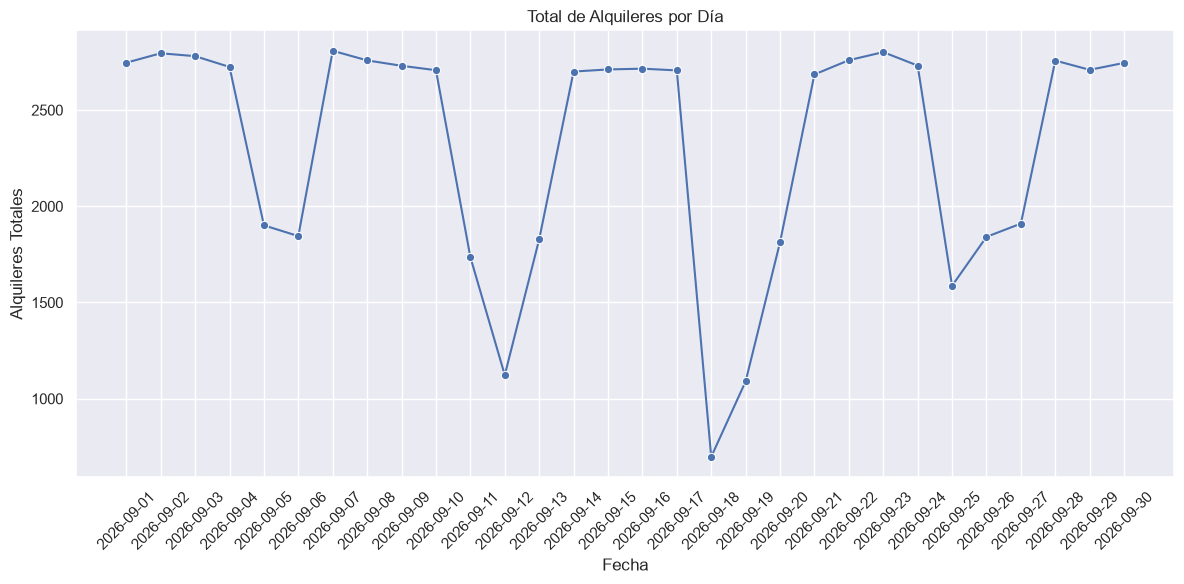

In [10]:
# Agrupar los alquileres totales por fecha
rentals_by_day = usage.groupby('date')['rentals'].sum().reset_index()

# Crear el gráfico de líneas
plt.figure(figsize=(12, 6))
sns.lineplot(data=rentals_by_day, x='date', y='rentals', marker='o', color='b')

plt.title('Total de Alquileres por Día')
plt.xlabel('Fecha')
plt.ylabel('Alquileres Totales')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [10]:
# 1. Sumar los alquileres por fecha manteniendo el día de la semana
daily_totals = usage.groupby(['date', 'weekday'])['rentals'].sum().reset_index()

# 2. Calcular la media de esos totales por día de la semana
weekday_average = daily_totals.groupby('weekday')['rentals'].mean().reset_index()

# Ordenar por el orden lógico de los días de la semana
weekday_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
weekday_average['weekday'] = pd.Categorical(weekday_average['weekday'], categories=weekday_order, ordered=True)
weekday_average = weekday_average.sort_values('weekday').reset_index(drop=True)

# Mostrar el resultado
display(weekday_average)

,weekday,rentals
0,Monday,2737.50
1,Tuesday,2736.60
2,Wednesday,2757.20
3,Thursday,2731.00
4,Friday,1686.25
5,Saturday,1488.75
6,Sunday,1849.00


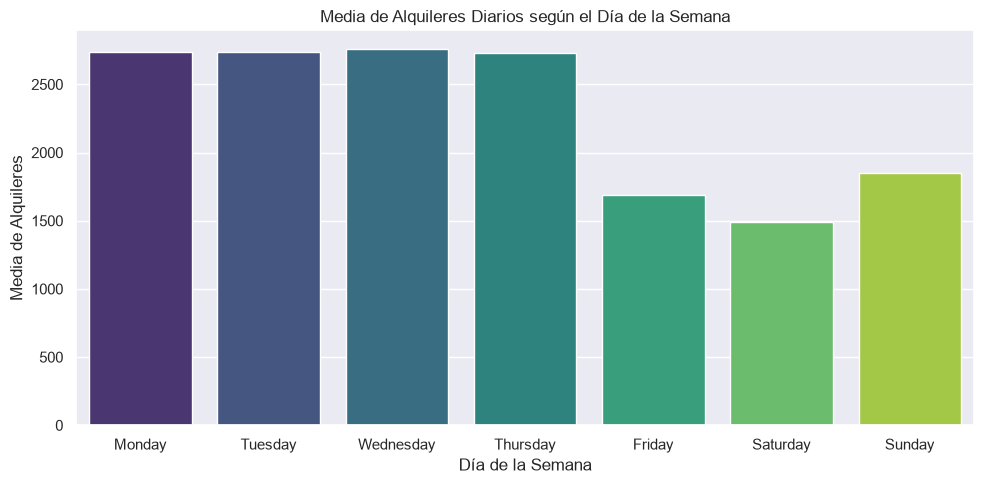

In [17]:
# Crear el gráfico de barras para la media de alquileres por día de la semana
plt.figure(figsize=(10, 5))
sns.barplot(data=weekday_average, x='weekday', y='rentals', palette='viridis', hue='weekday', legend=False, dodge = False)

plt.title('Media de Alquileres Diarios según el Día de la Semana')
plt.xlabel('Día de la Semana')
plt.ylabel('Media de Alquileres')
plt.tight_layout()
plt.show()

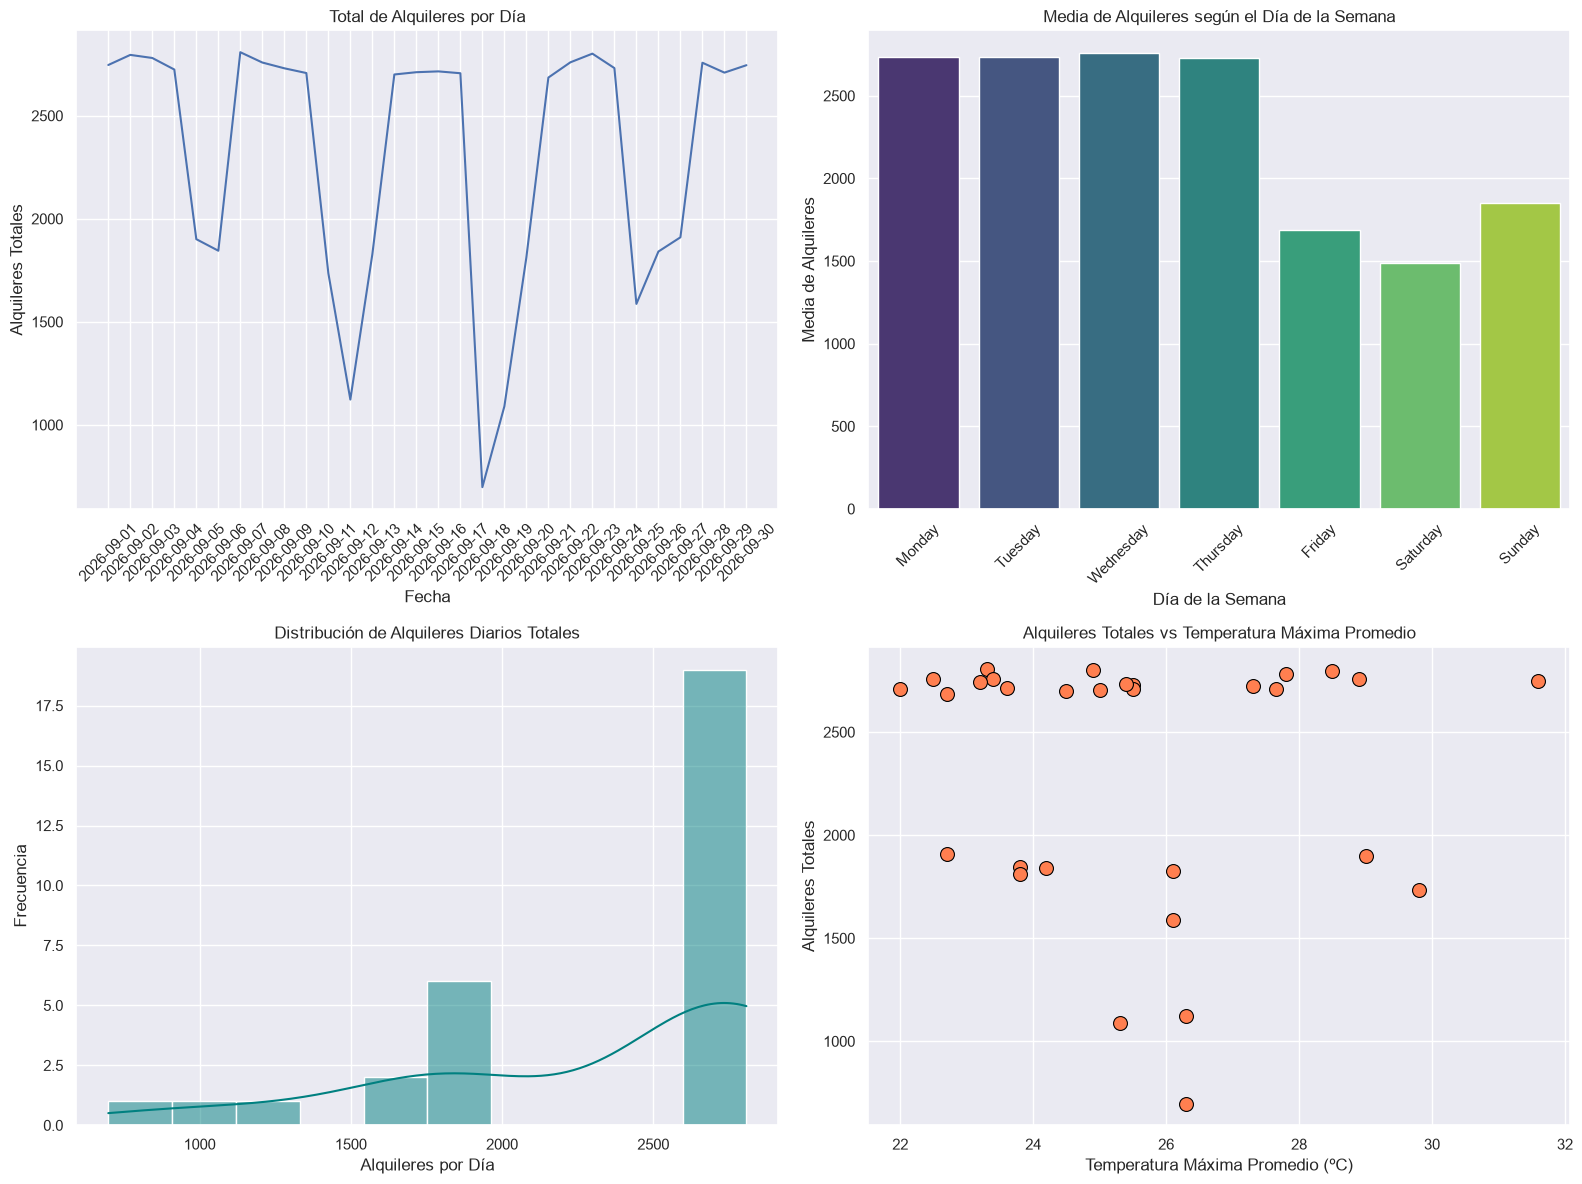

In [18]:
# 1. Preparar datos adicionales para la dispersión (alquileres y temperatura por fecha)
daily_weather_rentals = usage.groupby('date').agg({
    'rentals': 'sum',
    'temp_max': 'mean'
}).reset_index()

# Configurar la figura 2x2
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# [Subplot 0, 0] Gráfico de Barras: Alquileres totales por día
sns.lineplot(ax=axes[0, 0], data=rentals_by_day, x='date', y='rentals', color='b')
axes[0, 0].set_title('Total de Alquileres por Día')
axes[0, 0].set_xlabel('Fecha')
axes[0, 0].set_ylabel('Alquileres Totales')
axes[0, 0].tick_params(axis='x', rotation=45)

# [Subplot 0, 1] Gráfico de Barras: Media de alquileres por día de la semana
sns.barplot(ax=axes[0, 1], data=weekday_average, x='weekday', y='rentals', palette='viridis', hue='weekday', legend=False, dodge = False)
axes[0, 1].set_title('Media de Alquileres según el Día de la Semana')
axes[0, 1].set_xlabel('Día de la Semana')
axes[0, 1].set_ylabel('Media de Alquileres')
axes[0, 1].tick_params(axis='x', rotation=45)

# [Subplot 1, 0] Histograma: Distribución de los alquileres diarios totales
sns.histplot(ax=axes[1, 0], data=rentals_by_day, x='rentals', bins=10, kde=True, color='teal')
axes[1, 0].set_title('Distribución de Alquileres Diarios Totales')
axes[1, 0].set_xlabel('Alquileres por Día')
axes[1, 0].set_ylabel('Frecuencia')

# [Subplot 1, 1] Gráfico de Dispersión: Alquileres vs Temperatura Máxima Promedio
sns.scatterplot(ax=axes[1, 1], data=daily_weather_rentals, x='temp_max', y='rentals', s=100, color='coral', edgecolor='black')
axes[1, 1].set_title('Alquileres Totales vs Temperatura Máxima Promedio')
axes[1, 1].set_xlabel('Temperatura Máxima Promedio (ºC)')
axes[1, 1].set_ylabel('Alquileres Totales')

# Ajustar el diseño para evitar solapamientos
plt.tight_layout()
plt.show()